> **Web-runner version** of the Colab participant notebook. `data_dir` and `out_dir` are parameters set by the server; the last cell exports map layers for the viewer. Everything else is the original teaching material.

# Module 2 – Advanced Data Preparation and Management in R
**Participant notebook (R in Google Colab)**

This notebook contains every code cell of the training manual, in the same order and with the same step numbers, so you can run it alongside the manual. Run the cells from top to bottom; each topic depends on objects created earlier.

Before starting: **Runtime → Change runtime type → Language: R**. Then run the setup cells. When a session resets, run the setup cells again and continue where you were.

Text cells give the step; the manual has the explanations, the expected outputs and the figures, so compare your output with the manual after each cell.

## Setting up: Google Colab and R

As in Module 1 we run R in Google Colab. If you completed Module 1 you already know the routine: open an R notebook, run the install cell, run the download cell, work, and download anything you want to keep before the session ends. The points below are the same as in Module 1 with the names changed, plus one addition: in this module we build a project folder (/content/project) that Topic 5 turns into a reproducible pipeline, so from Topic 1 on we save into that folder rather than into a loose outputs folder.

### Opening an R notebook in Colab

### Getting the training data into Colab

Run this cell at the start of every session. The file ID is the long string in the sharing link between /d/ and /view; the facilitator will write it on the board.

In [ ]:
# Parameters: the web app (papermill) overrides these for every run.
data_dir    <- "/data/module2_data"
out_dir     <- "/srv/jobs/outputs"

In [ ]:
project_dir <- file.path(out_dir, "project")      # Module 2 builds its project folder here
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)
# a data zip with one extra top-level folder: step into it
.sub <- list.dirs(data_dir, recursive = FALSE); .fil <- list.files(data_dir)
if (length(.sub) == 1 && length(.fil) == 0) data_dir <- .sub
cat("Data directory:", data_dir, "\n")
list.files(data_dir, recursive = TRUE)

If the download fails, upload module2_data.zip through the Files panel (upload icon) and run only the unzip line and the lines after it.

### Installing the packages in Colab

Colab already has the tidyverse and sf. The rest are installed at the start of each session. This module's list is lighter than Module 1's; it takes two to five minutes.

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
suppressPackageStartupMessages({
  library(tidyverse); library(janitor); library(readxl); library(lubridate)
  library(stringdist); library(sf); library(terra); library(exactextractr)
})
options(width = 95)

If terra fails with a message about a missing system library, run the same apt-get line as in Module 1 and repeat the install.

### What each package is for

### Create the project folder now

Everything we keep goes into /content/project. Topic 5 explains the layout; for now just create it so that the save lines in Topics 1 to 4 work.

In [ ]:
for (d in c("data/raw", "data/reference", "data/interim", "data/processed", "R", "outputs", "docs"))
  dir.create(file.path(project_dir, d), recursive = TRUE, showWarnings = FALSE)
list.files(project_dir)

Remember that /content is wiped when the Colab session ends. At the end of the day, zip the project folder and download it: zip("/content/project.zip", "/content/project") then download from the Files panel. Topic 5 shows why that zip is worth keeping.

# Topic 1 – Importing and Structuring Institutional Data

## 1.4 Step by step in R with Ama's data

### Visual explainer: How the two institutional data sources differ

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
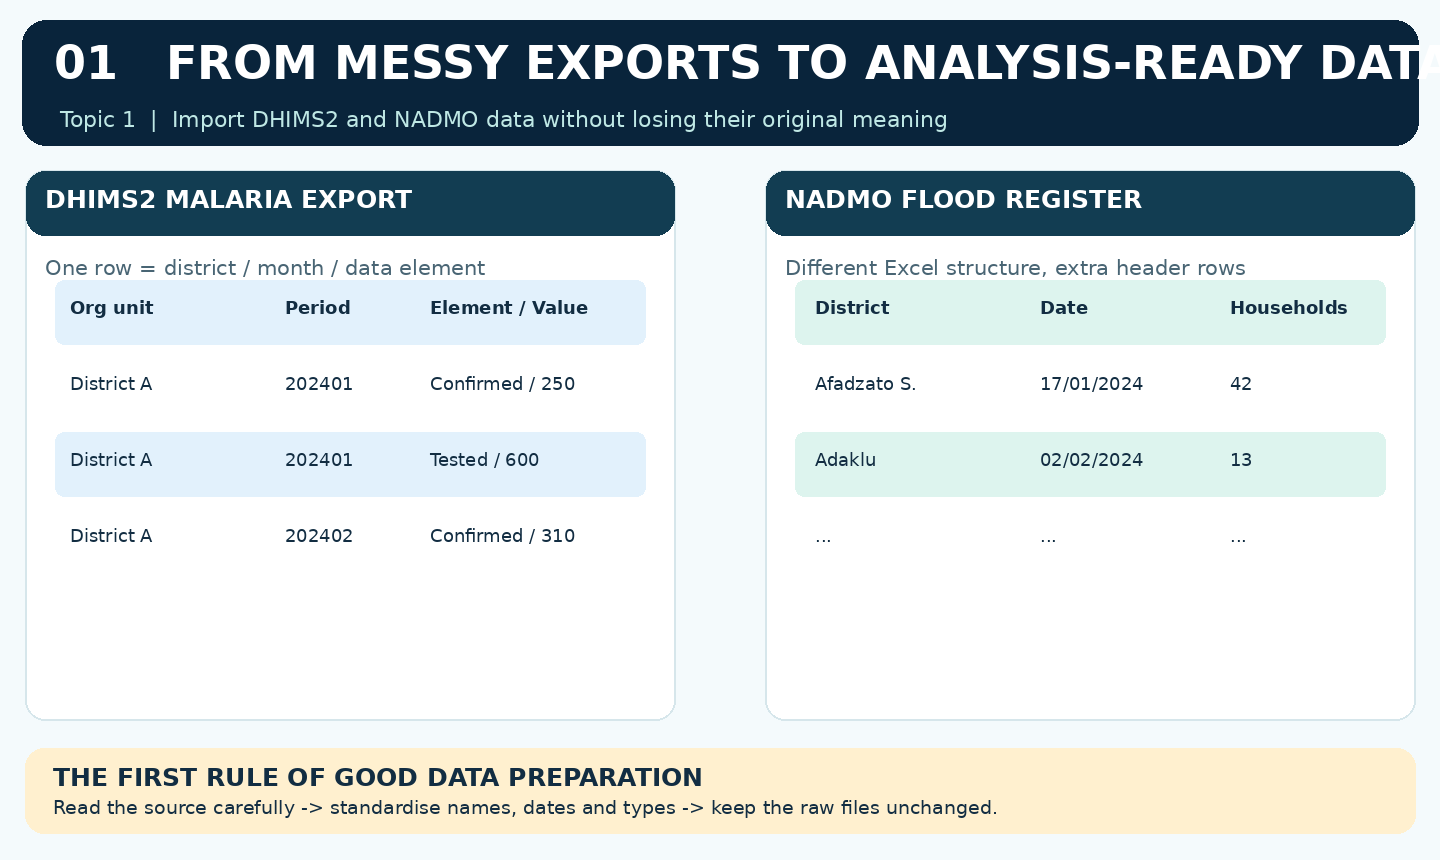
</div>


Step 1. Read the DHIMS2 export exactly as it is and look at it. Nothing is converted yet.

In [ ]:
dh_raw <- read_csv(file.path(data_dir, "dhims2_malaria_export.csv"))
head(dh_raw)
nrow(dh_raw)
dh_raw |> count(Data)
n_distinct(dh_raw$`Organisation unit`)

Three data elements, 260 organisation units and 16,729 rows. If every district reported every month there would be 3 x 260 x 24 = 18,720 rows, so about 2,000 district-month-indicator rows are missing. DHIMS2 does not export a row for a month with no report; the gap is invisible here and Topic 3 makes it visible.

Step 2. Clean the names, turn Period into a date, and shorten the data element to one word.

In [ ]:
dh <- dh_raw |>
  clean_names() |>                                   # Organisation unit -> organisation_unit
  mutate(month = ym(period),                         # "202301" -> 2023-01-01
         element = case_when(str_detect(data, "suspected") ~ "suspected",
                             str_detect(data, "tested")    ~ "tested",
                             str_detect(data, "confirmed") ~ "confirmed"))
glimpse(dh)
class(dh$month)
range(dh$month)
sum(is.na(dh$value))

glimpse() is the fastest way to see what type each column is. month is now <date>, which means the class check returns 'Date' and range() gives real dates. There are 15 blank values already; Topic 3 comes back to them.

Step 3. Read Kofi's register. First look at the raw sheet with skip = 2, then convert dates, households and the GPS column.

In [ ]:
nadmo_raw <- read_excel(file.path(data_dir, "nadmo_flood_register.xlsx"), sheet = "2023-2024", skip = 2)
head(nadmo_raw, 4)
nadmo <- nadmo_raw |>
  clean_names() |>
  mutate(date  = parse_date_time(date_of_incident, orders = c("dmy", "ymd", "dbY")) |> as.Date(),
         month = floor_date(date, "month"),
         households = parse_number(households_affected)) |>
  separate(gps_lat_long, into = c("lat", "lon"), sep = ",", convert = TRUE, fill = "right")
glimpse(nadmo)
sum(is.na(nadmo$date)); sum(is.na(nadmo$households)); sum(is.na(nadmo$lat))
nadmo |> count(month) |> head(6)

Every date parsed (0 NA), every household count parsed (0 NA), and 8 rows have no GPS, which matches the 8 blanks Kofi warned about. The month column lets the register be counted by month, which is what Ama needs to line it up with malaria later.

Step 4. Aggregate the register to district-month, then save both raw files and the provenance note into the project.

In [ ]:
nadmo_dm <- nadmo |>
  group_by(district, month) |>
  summarise(incidents = n(), households = sum(households, na.rm = TRUE), .groups = "drop")
head(nadmo_dm)
nrow(nadmo_dm)

dir.create(file.path(project_dir, "data/raw"), recursive = TRUE, showWarnings = FALSE)
write_rds(dh_raw,    file.path(project_dir, "data/raw/dhims2_malaria_export_raw.rds"))
write_rds(nadmo_raw, file.path(project_dir, "data/raw/nadmo_flood_register_raw.rds"))
writeLines(c("dhims2_malaria_export.csv: DHIMS2 Data Visualizer export, districts x months 2023-01 to 2024-12, three malaria data elements. Downloaded 2025-01-14 by A. Mensah.",
             "nadmo_flood_register.xlsx: NADMO northern-zone incident register, sheet 2023-2024, received by email from NADMO regional office 2025-01-10."),
           file.path(project_dir, "data/raw/PROVENANCE.txt"))
list.files(file.path(project_dir, "data/raw"))

Notice the district column in nadmo_dm: 'AFADZATO SOUTH' next to 'Adaklu'. Kofi's officers typed names as they liked. That is Topic 2's problem; Topic 1 leaves it alone on purpose, so the raw copy stays raw.

## 1.8 Trial test 1

Answer the trial test on paper (manual section 1.8). Answers are at the end of the manual.

# Topic 2 – Tidying, Reshaping and Harmonising Geography

## 2.4 Step by step in R with Ama's data

### Visual explainer: Why we reshape to one district-month row

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
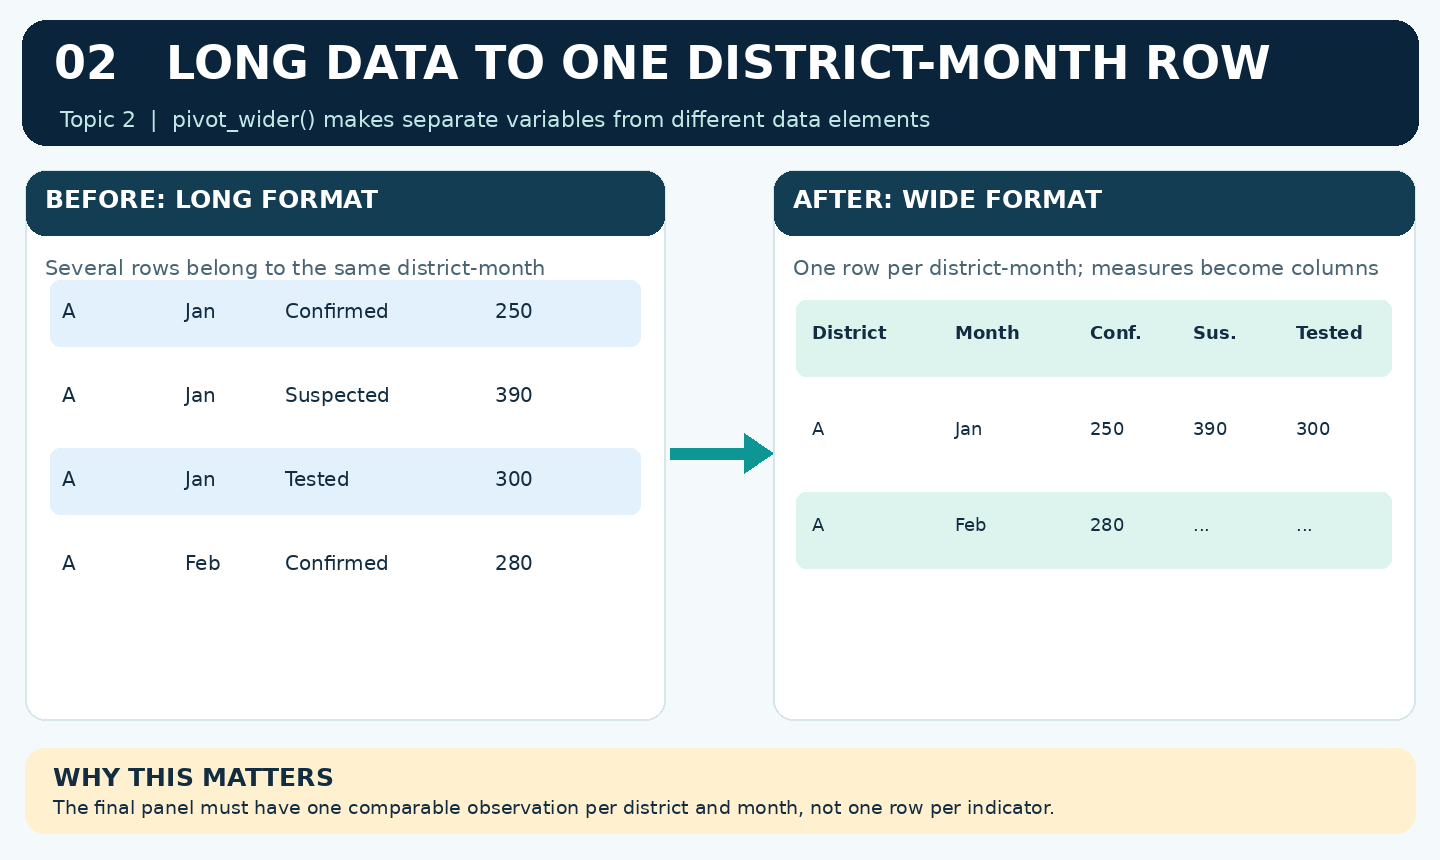
</div>


Step 1. Reshape the DHIMS2 table to one row per district-month.

In [ ]:
dh_wide <- dh |>
  select(organisation_unit, month, element, value) |>
  pivot_wider(names_from = element, values_from = value, values_fn = first)   # values_fn: see Topic 3 duplicates
head(dh_wide)
nrow(dh_wide)

5,568 district-months. With 260 districts and 24 months there should be 6,240, so 672 district-months have no rows at all. Keep that number; Topic 3 uses it.

### Visual explainer: Matching raw district names to official geography

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
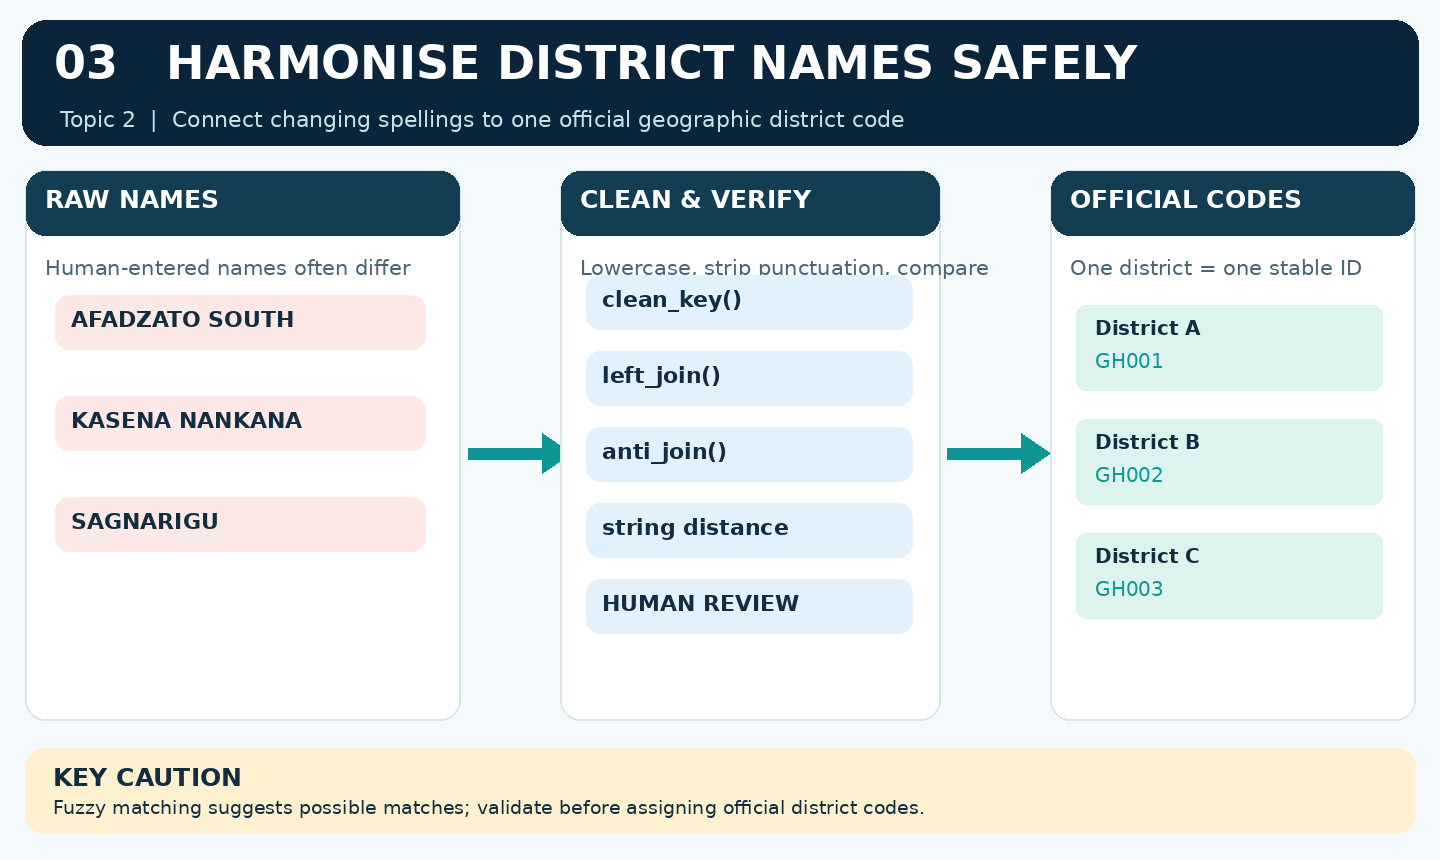
</div>


Step 2. Read the boundary file and the office lookup, define the key function, join, and list what did not match.

In [ ]:
districts <- st_read(file.path(data_dir, "ghana_districts.gpkg"), quiet = TRUE)
lookup    <- read_csv(file.path(data_dir, "district_lookup.csv"))
head(lookup); nrow(lookup)

clean_key <- function(x) x |> str_to_upper() |>
  str_replace_all("[-_/]", " ") |>
  str_remove("( (MUNICIPAL|MUNICIPALITY|METROPOLITAN|METROPOLIS|METRO|DISTRICT|MUN\\.)( ASSEMBLY)?)+$") |>
  str_squish()

dh_wide <- dh_wide |>
  mutate(key = clean_key(organisation_unit)) |>
  left_join(lookup |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name"))

unmatched <- dh_wide |> filter(is.na(adm2_code)) |> distinct(organisation_unit, key)
nrow(unmatched)
unmatched

The lookup has 221 rows and 39 DHIMS2 units did not match. Before looking for a clever fix, look at the list: ADENTA, AKATSI SOUTH, BONGO are perfectly ordinary keys. They are unmatched simply because the lookup never had them. That is the usual case.

Step 3. For each unmatched key, find the closest official district name and print the distance so a person can judge.

In [ ]:
official <- districts |> st_drop_geometry() |> transmute(adm2_code, adm2_name, off_key = clean_key(adm2_name))
suggest <- unmatched |>
  rowwise() |>
  mutate(best = official$adm2_name[which.min(stringdist(key, official$off_key, method = "jw"))],
         best_code = official$adm2_code[which.min(stringdist(key, official$off_key, method = "jw"))],
         distance = min(stringdist(key, official$off_key, method = "jw"))) |>
  ungroup() |> arrange(distance)
print(suggest, n = 50)

38 of the 39 have a distance of exactly 0: the key equals the official key, and the lookup was just incomplete. One, SAGNARIGU, is at 0.074 from the official Sagnerigu: a one-letter spelling difference. All 39 suggestions are correct, which is common when the source is DHIMS2 itself. Ama reads the whole list anyway; the day she does not is the day a wrong match goes in.

Step 4. Append the confirmed matches to the lookup with a note, save it into the project's reference folder, and join again.

In [ ]:
# add the confirmed matches to the lookup (a human checked the suggestions above)
additions <- suggest |>
  transmute(source_name = key, adm2_code = best_code, institution = "GHS", note = "added after fuzzy match, checked by AM 2025-01-15")
lookup2 <- bind_rows(lookup, additions)
write_csv(lookup2, file.path(project_dir, "data/reference/district_lookup.csv"))

dh_wide <- dh_wide |> select(-adm2_code) |>
  left_join(lookup2 |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name"))
sum(is.na(dh_wide$adm2_code))
n_distinct(dh_wide$adm2_code)
anti_join(dh_wide |> distinct(adm2_code), st_drop_geometry(districts), by = "adm2_code")

Zero unmatched, 260 distinct codes, and every code exists in the boundary file (the anti_join returns nothing). The DHIMS2 table is harmonised.

Step 5. The same for Kofi's register. His spellings are worse but the same three lines handle them.

In [ ]:
nadmo_dm <- nadmo_dm |> mutate(key = clean_key(district)) |>
  left_join(lookup2 |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name"))
nadmo_dm |> filter(is.na(adm2_code)) |> distinct(district, key)
nad_sugg <- nadmo_dm |> filter(is.na(adm2_code)) |> distinct(key) |> rowwise() |>
  mutate(best = official$adm2_name[which.min(stringdist(key, official$off_key, method = "jw"))],
         best_code = official$adm2_code[which.min(stringdist(key, official$off_key, method = "jw"))],
         distance = round(min(stringdist(key, official$off_key, method = "jw")), 3)) |> ungroup()
nad_sugg
lookup3 <- bind_rows(lookup2, nad_sugg |> transmute(source_name = key, adm2_code = best_code, institution = "NADMO", note = "fuzzy match checked by KA"))
write_csv(lookup3, file.path(project_dir, "data/reference/district_lookup.csv"))
nadmo_dm <- nadmo_dm |> select(-adm2_code) |>
  left_join(lookup3 |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name"))
sum(is.na(nadmo_dm$adm2_code))

Only four keys were unmatched after the lookup grew in Step 4, and note that the fuzzy matches include real misspellings (KASENA with one s), which is why the note says 'checked by KA': Kofi confirmed them.

### Visual explainer: How GPS corrections and point-in-polygon joins work

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
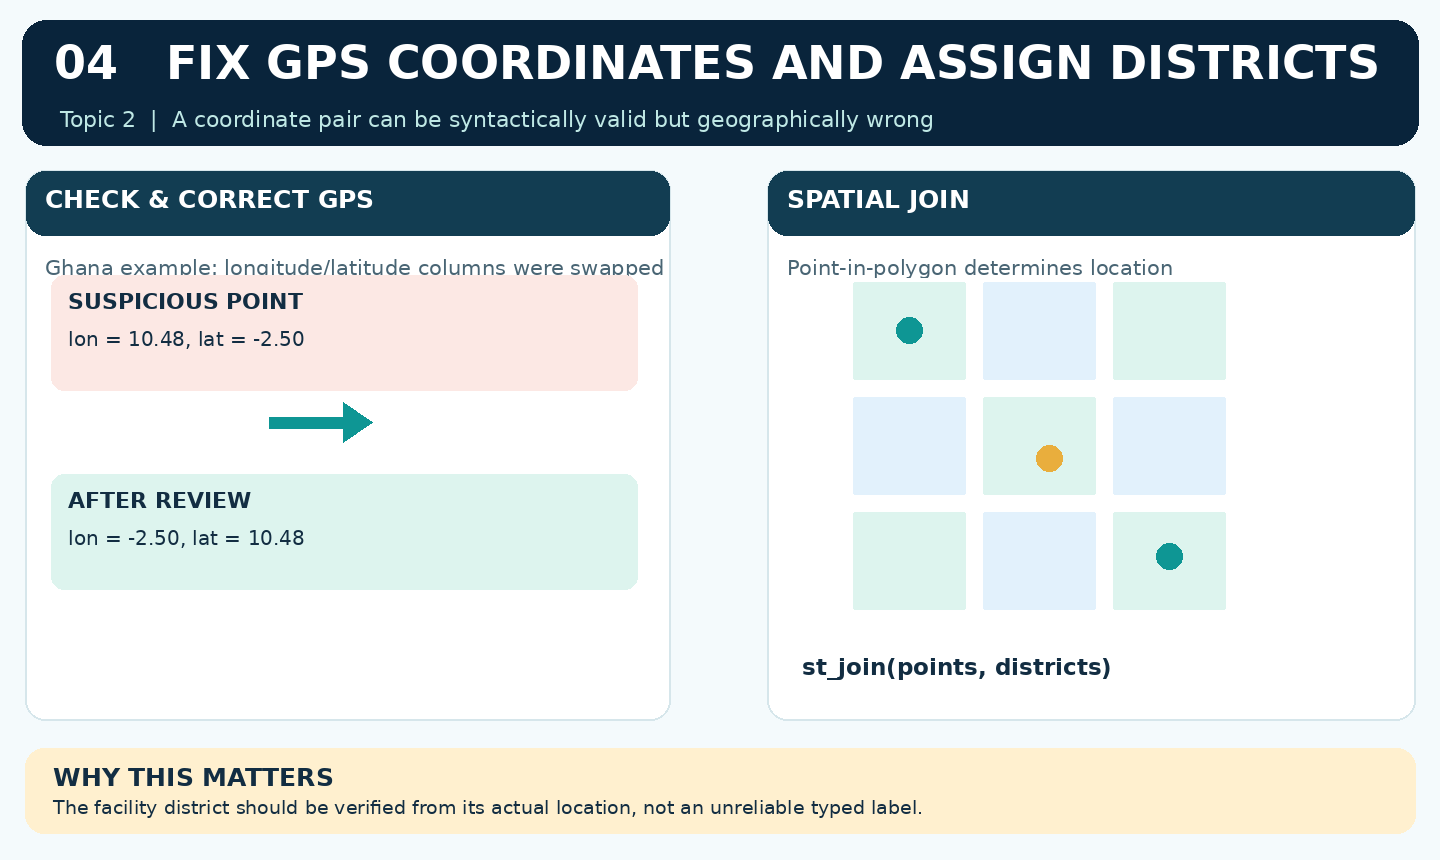
</div>


Step 6. Facilities: range-check the coordinates, swap the bad ones back, and ask the map which district each point sits in.

In [ ]:
fac <- read_csv(file.path(data_dir, "facility_master.csv"))
summary(fac$lon); summary(fac$lat)                      # Ghana: lon about -3.3 to 1.2, lat about 4.7 to 11.2
fac <- fac |> mutate(flag_swapped = lat < 4 | lat > 12 | lon < -4 | lon > 2)
sum(fac$flag_swapped)
fac <- fac |> mutate(lon2 = if_else(flag_swapped, lat, lon), lat2 = if_else(flag_swapped, lon, lat))   # swap them back
fac_sf <- st_as_sf(fac, coords = c("lon2", "lat2"), crs = 4326, remove = FALSE)
fac_sf <- st_join(fac_sf, districts |> select(adm2_code, spatial_district = adm2_name), join = st_within)
fac_sf <- fac_sf |> mutate(flag_wrong_district = !is.na(spatial_district) & spatial_district != district)
sum(fac_sf$flag_wrong_district)
fac_sf |> st_drop_geometry() |> filter(flag_wrong_district) |> select(facility_name, district, spatial_district) |> head(6)
all(st_is_valid(districts))

summary(fac$lon) has a maximum of 10.48, which is a latitude in the wrong column, and summary(fac$lat) has a minimum of -2.5, which is a longitude. 12 rows are flagged and swapped back. After the spatial join, 15 facilities sit in a district other than the one recorded. all(st_is_valid()) being TRUE confirms the polygons are usable for st_within.

Step 7. Count facilities per district using the district the point is actually in, and make sure districts with none get 0 rather than being dropped.

In [ ]:
# facilities per district, using the spatial district (where the point actually is)
fac_count <- fac_sf |> st_drop_geometry() |> count(adm2_code, name = "n_facilities")
anti_join(districts |> st_drop_geometry() |> select(adm2_code), fac_count, by = "adm2_code") |> nrow()   # districts with no facility
fac_count <- districts |> st_drop_geometry() |> select(adm2_code) |> left_join(fac_count, by = "adm2_code") |> mutate(n_facilities = replace_na(n_facilities, 0L))
summary(fac_count$n_facilities)

31 districts have no facility in this (synthetic) master list. A left_join from the full district list followed by replace_na() is the pattern that keeps them as zeros; a plain count() would silently lose them and Topic 4 would then have NA where it should have 0.

## 2.8 Trial test 2

Answer the trial test on paper (manual section 2.8). Answers are at the end of the manual.

# Topic 3 – Data Quality, Validation and Completeness

## 3.4 Step by step in R with Ama's data

### Visual explainer: Why missing is different from zero

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
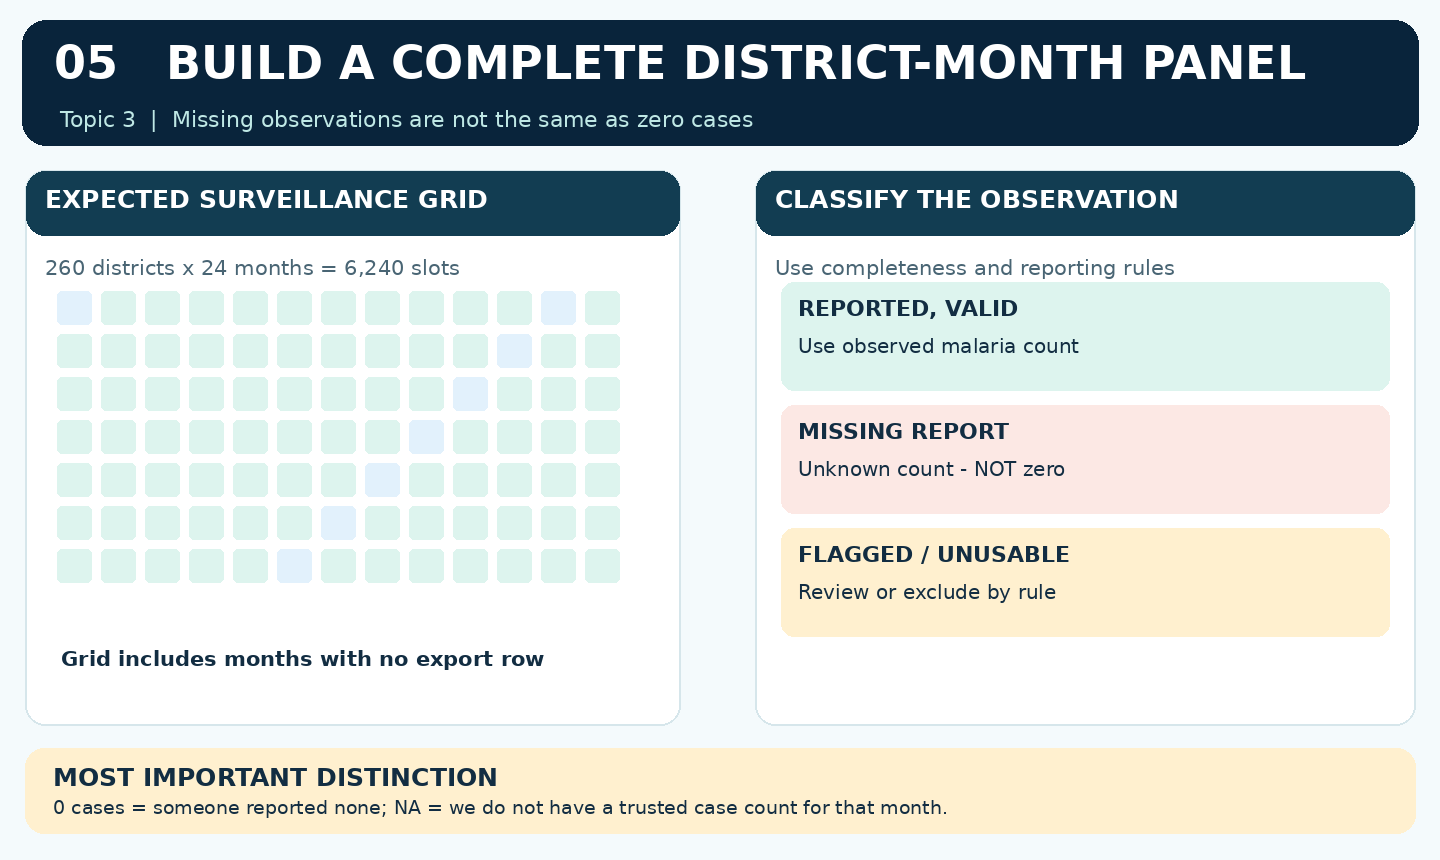
</div>


Step 1. Build the full 260 x 24 grid, join the cases, join the reporting rates, and define reported.

In [ ]:
months <- seq(as.Date("2023-01-01"), as.Date("2024-12-01"), by = "month")
grid <- expand_grid(adm2_code = districts$adm2_code, month = months)
nrow(grid)                                                 # 260 x 24
mal <- grid |> left_join(dh_wide |> select(adm2_code, month, suspected, tested, confirmed), by = c("adm2_code", "month"))
sum(is.na(mal$confirmed))                                  # months with no report at all, plus blank values
rr <- read_csv(file.path(data_dir, "dhims2_reporting_rates.csv")) |> clean_names() |>
  mutate(month = ym(period), key = clean_key(organisation_unit)) |>
  left_join(lookup3 |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name")) |>
  select(adm2_code, month, reporting_rate = value)
mal <- mal |> left_join(rr, by = c("adm2_code", "month")) |>
  mutate(reported = !is.na(confirmed) & reporting_rate >= 50)
mal |> count(reported)
mal |> group_by(adm2_code) |> summarise(completeness = mean(reported)) |> summarise(min = min(completeness), median = median(completeness), max = max(completeness))

6,240 rows in the grid; 684 have no confirmed value (672 district-months with no row at all plus a few blanks); after applying the 50 percent rule, 5,556 district-months count as reported. Completeness per district runs from 58 percent to 100 percent with a median of 92 percent.

Step 2. Find the duplicated rows in the long table and remove them.

In [ ]:
dh |> get_dupes(organisation_unit, month, element) |> nrow()
dh |> get_dupes(organisation_unit, month, element) |> head(6)
dh_dedup <- dh |> distinct(organisation_unit, month, element, .keep_all = TRUE)
nrow(dh); nrow(dh_dedup)

50 rows are involved in duplicates (25 pairs). In each pair the value is identical, so this is a repeated export line, not a conflict, and distinct() keeps one of each: 16,729 rows become 16,704. If two rows in a pair had carried different values, distinct() would have kept the first without telling you, so always look at the get_dupes() output before running distinct().

### Visual explainer: Why we flag questionable data before modelling

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
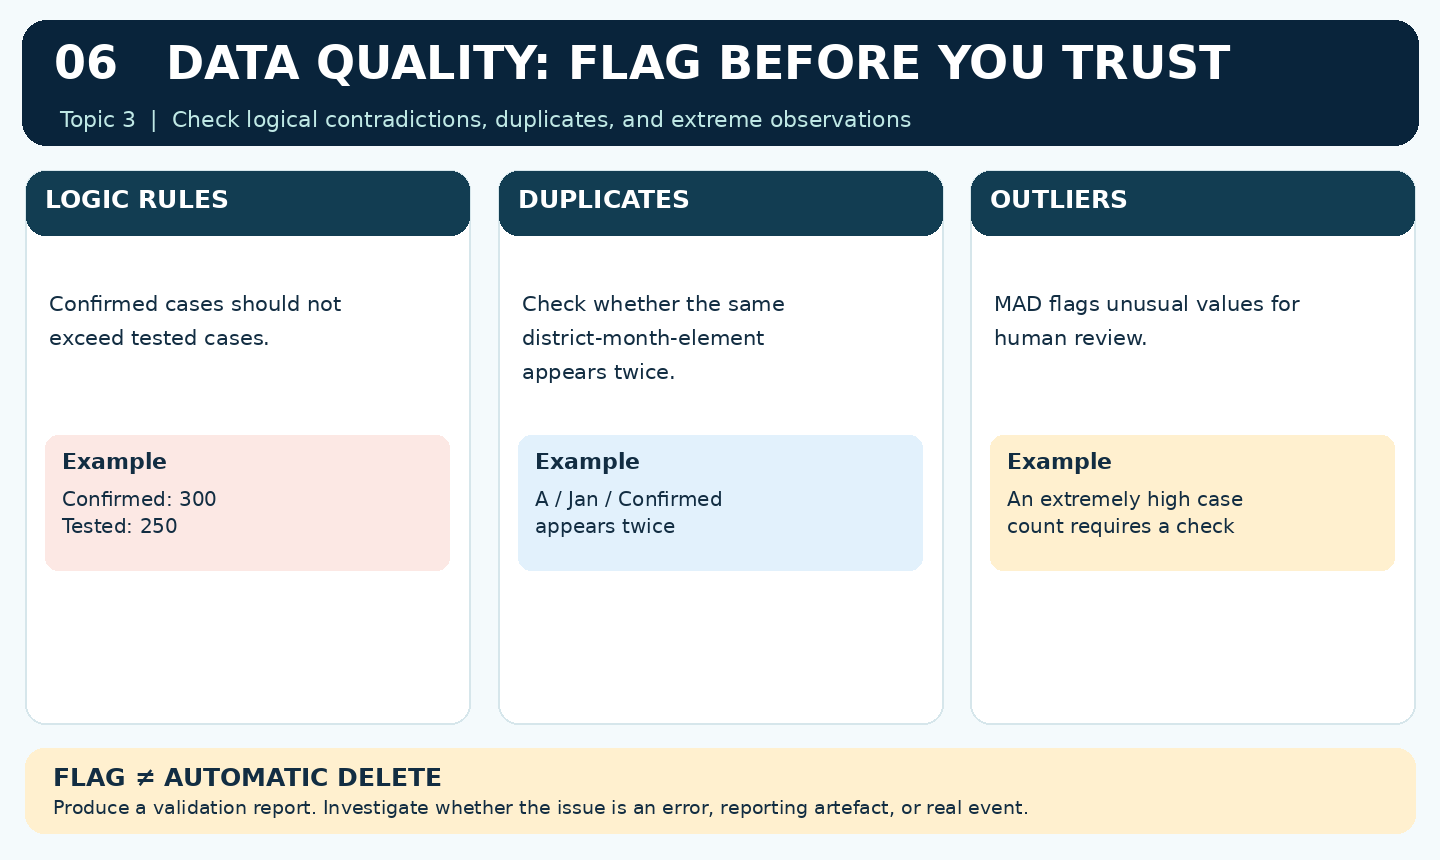
</div>


Step 3. Apply the logic rules and the MAD outlier rule, and count the flags.

In [ ]:
checked <- mal |>
  mutate(flag_conf_gt_test  = !is.na(confirmed) & !is.na(tested) & confirmed > tested,
         flag_test_gt_susp  = !is.na(tested) & !is.na(suspected) & tested > suspected,
         flag_blank_value   = reported & (is.na(suspected) | is.na(tested) | is.na(confirmed)),
         positivity         = confirmed / tested) |>
  group_by(adm2_code) |>
  mutate(med = median(confirmed, na.rm = TRUE), mad = mad(confirmed, na.rm = TRUE),
         flag_outlier = !is.na(confirmed) & mad > 0 & abs(confirmed - med) / mad > 5) |>
  ungroup()
checked |> summarise(across(starts_with("flag_"), ~ sum(.x, na.rm = TRUE)))
checked |> filter(flag_outlier) |> select(adm2_code, month, confirmed, med, mad) |> head()

13 months where confirmed exceeds tested, none where tested exceeds suspected, 3 blank values inside reported months, and 7 outliers. GH199 is Bongo, August 2024: 17,610 confirmed against a district median of 702, which is a score of about 27 MADs. The other six outliers are between about 5 and 12 MADs and are the kind of thing an epidemic season produces; Ama will look at each on a plot before deciding whether to exclude them.

Step 4. Write the validation report: every row with any flag, with district names, in one CSV.

In [ ]:
report <- checked |>
  filter(if_any(starts_with("flag_"))) |>
  left_join(districts |> st_drop_geometry() |> select(adm2_code, adm2_name), by = "adm2_code") |>
  select(adm2_name, month, suspected, tested, confirmed, starts_with("flag_")) |>
  arrange(adm2_name, month)
nrow(report)
write_csv(report, file.path(project_dir, "outputs/validation_report.csv"))
report |> count(adm2_name, sort = TRUE) |> head(10)

16 district-months carry at least one flag (some carry two). The CSV in project/outputs is what Ama sends to the regional data manager; it is the only output of this topic that leaves R.

## 3.8 Trial test 3

Answer the trial test on paper (manual section 3.8). Answers are at the end of the manual.

# Topic 4 – Building Predictors from Spatial Layers

## 4.4 Step by step in R with Ama's data

Step 1. Route A: the DHIMS2 Climate App export, reshaped and coded exactly like the case export.

In [ ]:
clim_a <- read_csv(file.path(data_dir, "dhims2_climate_app_export.csv")) |> clean_names() |>
  mutate(month = ym(period), key = clean_key(organisation_unit),
         var = if_else(str_detect(data, "precipitation"), "rain_mm", "tmean_c")) |>
  left_join(lookup3 |> mutate(source_name = clean_key(source_name)) |> distinct(source_name, adm2_code), by = c("key" = "source_name")) |>
  select(adm2_code, month, var, value) |>
  pivot_wider(names_from = var, values_from = value)
head(clim_a); nrow(clim_a); sum(is.na(clim_a$adm2_code))

6,240 rows, none unmatched: the lookup from Topic 2 already covers the Climate App's spellings because they are the DHIMS2 spellings.

Step 2. Route B: the rasters. Stack the 24 rainfall files and the 24 temperature files, convert kelvin, and average each layer inside each district.

In [ ]:
rain_files <- c(sprintf("%s/rasters/chirps_2023_%02d.tif", data_dir, 1:12), sprintf("%s/rasters/chirps_2024_%02d.tif", data_dir, 1:12))
temp_files <- c(sprintf("%s/rasters/era5_temp_2023_%02d.tif", data_dir, 1:12), sprintf("%s/rasters/era5_temp_2024_%02d.tif", data_dir, 1:12))
rain <- rast(rain_files); names(rain) <- format(months, "%Y-%m")
temp <- rast(temp_files) - 273.15; names(temp) <- format(months, "%Y-%m")
d_wgs <- st_transform(districts, crs(rain))
clim_b <- bind_cols(
  exact_extract(rain, d_wgs, "mean", progress = FALSE) |> mutate(adm2_code = d_wgs$adm2_code) |>
    pivot_longer(-adm2_code, names_to = "month", values_to = "rain_mm") |> mutate(month = ym(str_remove(month, "mean."))),
  exact_extract(temp, d_wgs, "mean", progress = FALSE) |> pivot_longer(everything(), values_to = "tmean_c") |> select(tmean_c))
head(clim_b); nrow(clim_b)
# the two routes agree
comp <- inner_join(clim_a, clim_b, by = c("adm2_code", "month"), suffix = c("_app", "_raster"))
summary(comp$rain_mm_app - comp$rain_mm_raster)

The difference between the two routes is between -0.05 and +0.05 mm, which is the rounding of the app export. The raster route is the one Ama keeps in the pipeline, because Kofi, Efua and Yaw can run it without a DHIMS2 account.

Step 3. Static predictors: mean elevation, mean NDVI, area in square kilometres, and the facility count from Topic 2.

In [ ]:
elev <- rast(file.path(data_dir, "rasters/srtm_ghana.tif")); ndvi <- rast(file.path(data_dir, "rasters/ndvi_2024.tif"))
pop  <- read_csv(file.path(data_dir, "population_district.csv"))
static <- d_wgs |>
  mutate(elev_m = exact_extract(elev, d_wgs, "mean", progress = FALSE),
         ndvi   = exact_extract(ndvi, d_wgs, "mean", progress = FALSE),
         area_km2 = as.numeric(st_area(st_transform(d_wgs, 32630))) / 1e6) |>
  st_drop_geometry() |> select(adm2_code, elev_m, ndvi, area_km2) |>
  left_join(fac_count, by = "adm2_code")
head(static)

### Visual explainer: How climate, population and static predictors form a panel

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
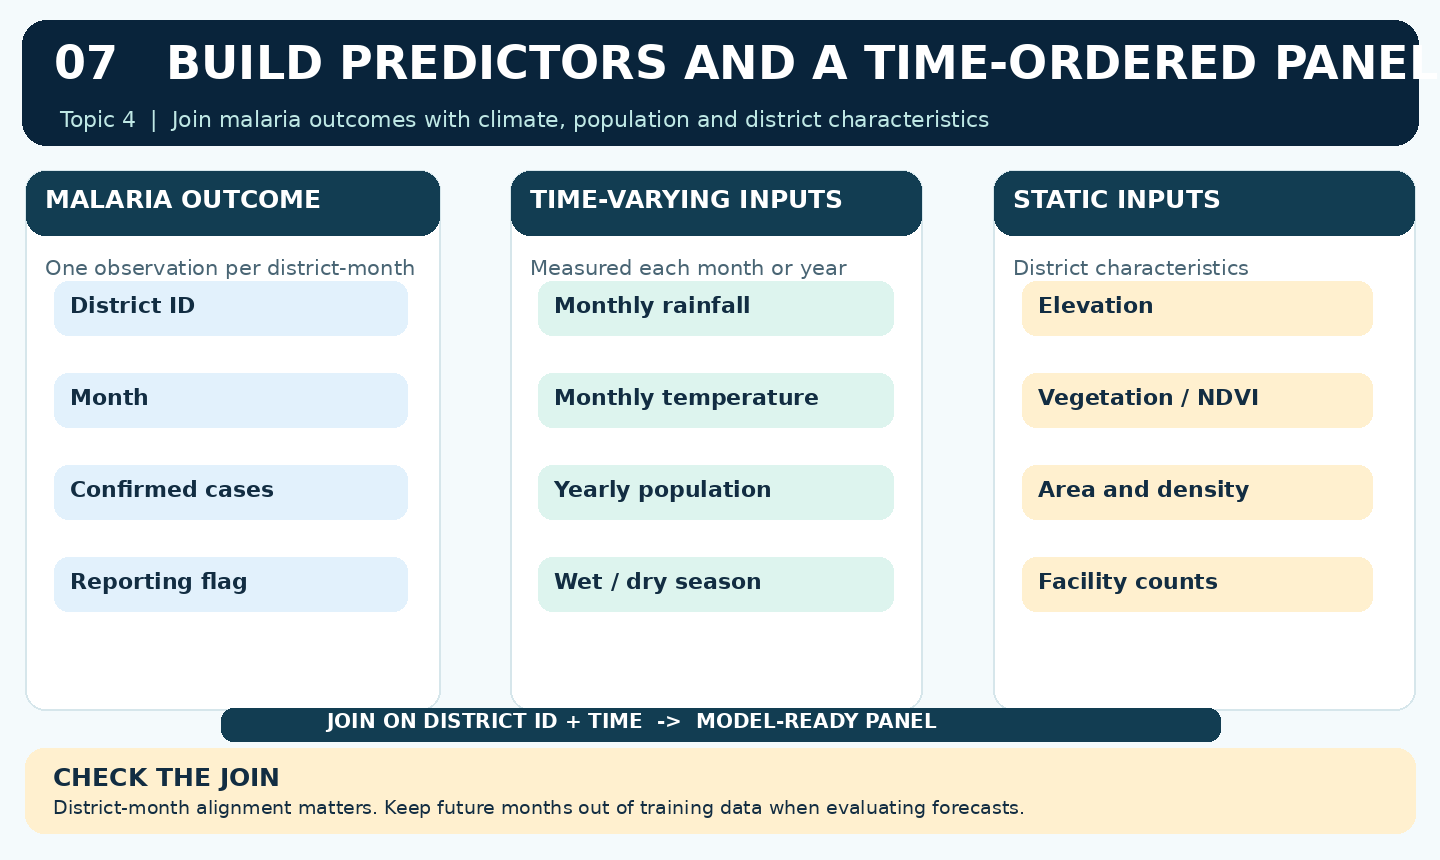
</div>


Step 4. Assemble the panel: checked cases, population by year, climate by month, static predictors, then the derived variables.

In [ ]:
panel <- checked |>
  select(adm2_code, month, suspected, tested, confirmed, reported, reporting_rate, starts_with("flag_")) |>
  mutate(year = year(month)) |>
  left_join(pop, by = c("adm2_code", "year")) |>
  left_join(clim_b, by = c("adm2_code", "month")) |>
  left_join(static, by = "adm2_code") |>
  mutate(incidence_1000 = confirmed / population * 1000,
         pop_density    = population / area_km2,
         fac_per_10k    = n_facilities / population * 1e4) |>
  arrange(adm2_code, month) |>
  group_by(adm2_code) |>
  mutate(rain_lag1  = lag(rain_mm, 1), rain_lag2 = lag(rain_mm, 2), tmean_lag1 = lag(tmean_c, 1),
         cases_lag1 = lag(confirmed, 1)) |>
  ungroup() |>
  mutate(month_of_year = month(month),
         season = if_else(month_of_year %in% 4:10, "wet", "dry"),
         split  = if_else(month <= ymd("2024-06-01"), "train", "test"))
anti_join(panel, clim_b, by = c("adm2_code", "month")) |> nrow()     # expect 0
sum(is.na(panel$population)); sum(is.na(panel$rain_mm))
panel |> count(split)
panel |> filter(adm2_code == "GH198") |> select(month, confirmed, population, incidence_1000, rain_mm, rain_lag1, rain_lag2, season, split) |> print(n = 8)

Every district-month found its climate row (0 missing), no population or rainfall is missing, 4,680 rows are training months and 1,560 are test months. The printed rows are Bolgatanga Municipal: June 2023 is NA because that month was not reported, and the lags line up as in the hand example.

## 4.8 Trial test 4

Answer the trial test on paper (manual section 4.8). Answers are at the end of the manual.

# Topic 5 – Reproducible Data Management

## 5.4 Step by step in R with Ama's data

### Visual explainer: From raw exports to reproducible outputs

This beginner infographic introduces the next code step. Read the diagram from left to right before running the cell.

<div style="text-align:center; margin: 12px 0 24px 0;">
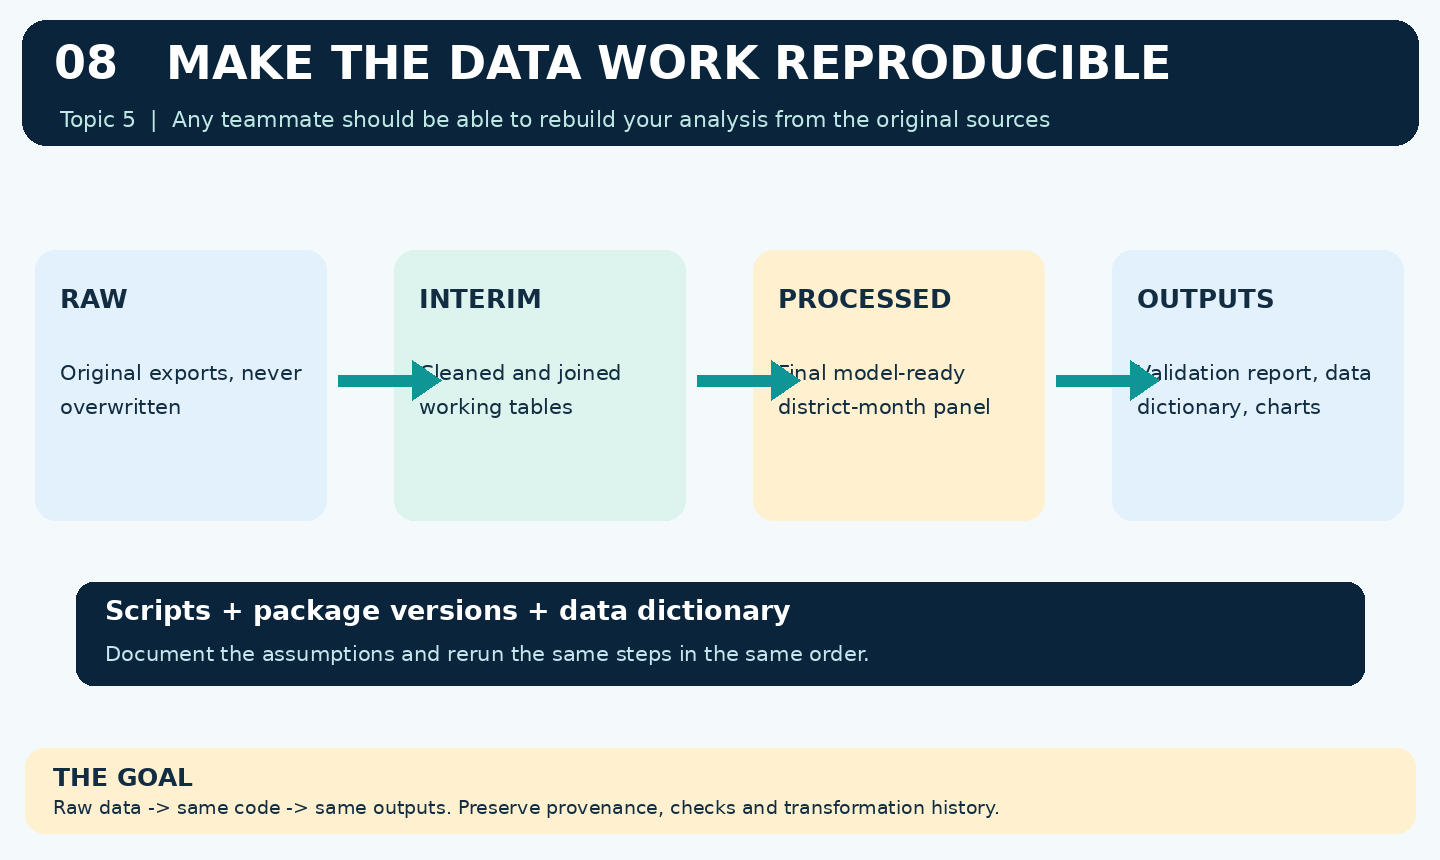
</div>


Step 1. Create the folders (already done in setup; the line is harmless if they exist), save the interim tables and the panel in three formats, and look at the tree.

In [ ]:
dirs <- c("data/raw", "data/reference", "data/interim", "data/processed", "R", "outputs", "docs")
for (d in dirs) dir.create(file.path(project_dir, d), recursive = TRUE, showWarnings = FALSE)
write_rds(checked, file.path(project_dir, "data/interim/malaria_checked.rds"))
write_rds(clim_b,  file.path(project_dir, "data/interim/climate_district_month.rds"))
write_rds(static,  file.path(project_dir, "data/interim/static_predictors.rds"))
write_rds(panel,   file.path(project_dir, "data/processed/panel.rds"))
write_csv(panel,   file.path(project_dir, "data/processed/panel.csv"))
panel_sf <- districts |> select(adm2_code) |> left_join(panel, by = "adm2_code")
st_write(panel_sf, file.path(project_dir, "data/processed/panel.gpkg"), delete_dsn = TRUE, quiet = TRUE)
fs::dir_tree(project_dir, recurse = 2)
round(file.size(c(file.path(project_dir, "data/processed/panel.rds"), file.path(project_dir, "data/processed/panel.csv"), file.path(project_dir, "data/processed/panel.gpkg"))) / 1e6, 2)

The three sizes at the end are megabytes: the .rds is smallest, the .csv a little larger, and the .gpkg is 260 MB because it repeats the district geometry on every one of the 24 monthly rows. That is the price of a spatial file with a panel inside it; keep it because QGIS users can open it, but the .rds is what the next module reads.

Step 2. The data dictionary, typed once with tribble() and saved as CSV.

In [ ]:
dictionary <- tribble(
  ~variable,        ~meaning,                                              ~unit,        ~source,
  "adm2_code",      "District code, join key",                            "code",       "ghana_districts.gpkg",
  "month",          "First day of the reporting month",                   "date",       "DHIMS2 period",
  "suspected",      "Suspected malaria cases, OPD",                       "count",      "DHIMS2 export",
  "tested",         "Malaria tests done (RDT + microscopy)",              "count",      "DHIMS2 export",
  "confirmed",      "Confirmed malaria cases, OPD",                       "count",      "DHIMS2 export",
  "reported",       "Report received and reporting rate >= 50%",          "TRUE/FALSE", "derived",
  "reporting_rate", "Monthly form reporting rate",                        "percent",    "DHIMS2 reporting rates",
  "flag_*",         "Validation rule violations, never deleted",          "TRUE/FALSE", "derived",
  "population",     "Mid-year district population",                       "people",     "population_district.csv",
  "incidence_1000", "confirmed / population x 1000",                      "per 1,000",  "derived",
  "rain_mm",        "Mean monthly rainfall in the district",              "mm",         "CHIRPS rasters or Climate App",
  "tmean_c",        "Mean monthly temperature",                           "deg C",      "ERA5 rasters (kelvin converted)",
  "rain_lag1/2",    "Rainfall one / two months earlier",                  "mm",         "derived",
  "cases_lag1",     "Confirmed cases one month earlier",                  "count",      "derived",
  "elev_m, ndvi",   "District mean elevation and NDVI",                   "m, index",   "SRTM, MODIS rasters",
  "pop_density",    "population / area",                                  "per km2",    "derived",
  "fac_per_10k",    "Facilities per 10,000 people (spatially checked)",   "per 10,000", "facility_master.csv",
  "season, split",  "wet/dry; train (to 2024-06) / test (2024-07 on)",    "label",      "derived")
write_csv(dictionary, file.path(project_dir, "docs/data_dictionary.csv"))
print(dictionary, n = 30)

Step 3. Package versions.

In [ ]:
pkgs <- c("tidyverse", "janitor", "readxl", "lubridate", "stringdist", "sf", "terra", "exactextractr")
versions <- tibble(package = pkgs, version = sapply(pkgs, function(p) as.character(packageVersion(p))))
versions
write_csv(bind_rows(versions, tibble(package = "R", version = paste(R.version$major, R.version$minor, sep = "."))),
          file.path(project_dir, "docs/package_versions.csv"))

Step 4. Turn the notebook into scripts. In the Colab Files panel, open project/R, right-click, New file, name it 01_import.R, double-click to open the editor, paste in the cells of Topic 1 in order (Steps 1 to 4), and save with Ctrl+S. Do the same for 02_tidy_harmonise.R (Topic 2, Steps 1 to 7), 03_validate.R (Topic 3, Steps 1 to 4), 04_predictors.R (Topic 4, Steps 1 to 4) and 05_assemble_save.R (Topic 5, Step 1). Put the library() block from the setup at the top of each script. Then write the runner and run it.

In [ ]:
# The notebook cells saved as scripts in order, plus one runner.
# In the workshop participants create project/R/01_import.R ... 05_assemble_save.R by hand (Step 4).
# That is a manual exercise, so the runner only replays the pipeline if those scripts exist.
scripts <- file.path(project_dir, "R", c("01_import.R", "02_tidy_harmonise.R", "03_validate.R", "04_predictors.R", "05_assemble_save.R"))
if (all(file.exists(scripts))) {
  run_all <- c(paste0("data_dir <- \"", data_dir, "\""),
               "source(\"R/01_import.R\")", "source(\"R/02_tidy_harmonise.R\")",
               "source(\"R/03_validate.R\")", "source(\"R/04_predictors.R\")", "source(\"R/05_assemble_save.R\")",
               "cat(\"Pipeline complete:\", nrow(panel), \"rows\\n\")")
  writeLines(run_all, file.path(project_dir, "run_all.R"))
  old <- setwd(project_dir); source("run_all.R"); setwd(old)
  panel2 <- read_rds(file.path(project_dir, "data/processed/panel.rds"))
  identical(dim(panel), dim(panel2)); all.equal(panel$confirmed, panel2$confirmed)
} else {
  message("Skipped: the R/ scripts are a hands-on exercise (manual step 4); nothing to replay in an unattended run.")
}

The runner rebuilt the panel from the raw exports, and the rebuilt panel has the same dimensions and the same confirmed column as the one in the notebook (TRUE, TRUE). The project is reproducible. Zip it and download it: zip("/content/project.zip", "/content/project").

## 5.8 Trial test 5

Answer the trial test on paper (manual section 5.8). Answers are at the end of the manual.

---
End of the module. Download anything you want to keep from the Files panel before the session ends.

## Export for the web map viewer

Added by `tools/prepare_notebooks.py`: writes the map layers listed in `layers.json`.

In [ ]:
# ---- Export for the web map viewer (added by tools/prepare_notebooks.py) ----
# Each block below is wrapped in safe(): if a step was edited or skipped, the other layers are
# still written. The viewer discovers everything through layers.json.
layers <- list()
safe <- function(label, expr) tryCatch(expr, error = function(e)
  message("Export skipped - ", label, ": ", conditionMessage(e)))
add_layer <- function(...) layers[[length(layers) + 1]] <<- list(...)
wgs <- function(x) sf::st_transform(x, 4326)

# district polygons, in lon/lat, lightly simplified for the web
web_districts <- function(d, tol = 0.002) {
  d <- wgs(d)
  keep <- intersect(c("adm2_code", "adm2_name", "region", "eco_zone"), names(d))
  suppressWarnings(sf::st_simplify(d[, keep], preserveTopology = TRUE, dTolerance = tol))
}
write_geojson <- function(x, name) {
  f <- file.path(out_dir, paste0(name, ".geojson"))
  if (file.exists(f)) file.remove(f)
  x <- dplyr::mutate(x, dplyr::across(dplyr::where(is.numeric), ~ round(.x, 4)))
  sf::st_write(x, f, driver = "GeoJSON", quiet = TRUE, layer_options = "COORDINATE_PRECISION=5")
}
# long district-month table -> one column per month (inc_2024_01, ...) + field list for the slider
widen_months <- function(df, value, prefix) {
  df <- as.data.frame(df)
  d  <- data.frame(adm2_code = df$adm2_code, key = paste0(prefix, "_", format(df$month, "%Y_%m")), v = df[[value]])
  m  <- sort(unique(df$month))
  list(wide   = tidyr::pivot_wider(d, names_from = "key", values_from = "v"),
       fields = lapply(m, function(x) list(field = paste0(prefix, "_", format(x, "%Y_%m")), label = format(x, "%b %Y"))))
}
# x/y/value data frame -> heat-point JSON for the browser + a GeoTIFF for GIS users
heat_export <- function(df, name, crs = 32630, max_pts = 25000) {
  df <- df[is.finite(df$value), c("x", "y", "value")]
  tryCatch(terra::writeRaster(terra::rast(df, type = "xyz", crs = paste0("EPSG:", crs)),
                              file.path(out_dir, paste0(name, ".tif")), overwrite = TRUE),
           error = function(e) message("GeoTIFF skipped for ", name, ": ", conditionMessage(e)))
  if (nrow(df) > max_pts) df <- df[round(seq(1, nrow(df), length.out = max_pts)), ]
  ll <- sf::st_coordinates(wgs(sf::st_as_sf(df, coords = c("x", "y"), crs = crs)))
  jsonlite::write_json(list(points = data.frame(lat = ll[, 2], lng = ll[, 1], value = df$value)),
                       file.path(out_dir, paste0(name, ".heat.json")), digits = 6)
}
im_df  <- function(im) { d <- as.data.frame(im); names(d)[3] <- "value"; d }          # spatstat image
pts_df <- function(s, col) { xy <- sf::st_coordinates(s); data.frame(x = xy[, 1], y = xy[, 2], value = s[[col]]) }

# Data-quality maps and the district-month incidence series from the finished panel
safe("data quality", {
  pn <- panel |> dplyr::mutate(usable = reported & !flag_outlier,
                               inc = dplyr::if_else(usable, incidence_1000, NA_real_))
  dq <- pn |> dplyr::group_by(adm2_code) |>
    dplyr::summarise(months_reported = sum(reported, na.rm = TRUE),
                     pct_usable = 100 * mean(usable, na.rm = TRUE),
                     reporting_rate_mean = mean(reporting_rate, na.rm = TRUE),
                     months_flagged = sum(dplyr::if_any(dplyr::starts_with("flag_"), ~ .x %in% TRUE)),
                     confirmed_total = sum(confirmed, na.rm = TRUE),
                     incidence_mean = mean(inc, na.rm = TRUE), .groups = "drop")
  mo <- widen_months(pn, "inc", "inc")
  d  <- web_districts(districts) |> dplyr::left_join(dq, by = "adm2_code") |> dplyr::left_join(mo$wide, by = "adm2_code")
  write_geojson(d, "panel_districts")
  add_layer(id = "quality", title = "Data quality of the panel", kind = "choropleth", file = "panel_districts.geojson",
    fields = list(
      list(field = "pct_usable",          label = "Usable district-months (%)", type = "numeric"),
      list(field = "months_reported",     label = "Months reported (of 24)", type = "numeric"),
      list(field = "months_flagged",      label = "Months with a validation flag", type = "numeric"),
      list(field = "reporting_rate_mean", label = "Mean reporting rate (%)", type = "numeric"),
      list(field = "incidence_mean",      label = "Mean monthly incidence per 1,000", type = "numeric"),
      list(field = "confirmed_total",     label = "Confirmed cases, 24 months", type = "numeric")))
  add_layer(id = "monthly", title = "Monthly incidence per 1,000", kind = "choropleth", file = "panel_districts.geojson",
    series = list(list(id = "inc", label = "Usable months only", fields = mo$fields))) })

# Hand-off: the files Modules 3, 4 and 5 expect, so the next run can use this run as its dataset
safe("handoff", {
  h <- file.path(out_dir, "handoff"); dir.create(h, showWarnings = FALSE, recursive = TRUE)
  readr::write_rds(panel, file.path(h, "panel.rds"))
  readr::write_csv(panel, file.path(h, "panel.csv"))
  if (exists("dictionary")) readr::write_csv(dictionary, file.path(h, "data_dictionary.csv"))
  file.copy(file.path(data_dir, "ghana_districts.gpkg"), file.path(h, "ghana_districts.gpkg"), overwrite = TRUE)
  message("Hand-off folder ready: ", paste(list.files(h), collapse = ", ")) })

jsonlite::write_json(list(layers = layers), file.path(out_dir, "layers.json"),
                     auto_unbox = TRUE, null = "null", na = "null")
cat("Exported", length(layers), "map layer(s) to", out_dir, "\n")
print(list.files(out_dir))
